# U.S. validation and final model

We use the 26,945 official training campaigns. Reserved IDs and `y_test.csv` are not loaded. Existing tuning notebooks and Zasha's combined experiment stay unchanged.

Each outer fold holds out one third of training rows. Two inner folds compare the existing settings within each model family, then select across families by AUC. Preprocessing is fitted inside every split. This small nested comparison estimates the restricted selection procedure, not the original randomized searches. Prior tuning on these same campaigns still limits independence. The threshold stays at 0.5.

Run `06_us_accuracy_experiments.ipynb` first. It checks two focused HGB changes and inner-selected thresholds. No change passed the promotion rules, so we retain the original tuned HGB with threshold .5.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'utils/preprocessing.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import ConfusionMatrixDisplay
from utils.us_modeling import load_us_training_data
from utils.us_validation import (INPUTS, LIMITATIONS, nested_comparison, metrics,
                                 error_breakdowns, save_primary)
X, y, project_ids = load_us_training_data(ROOT)
X = X[INPUTS].copy()
assert len(X) == 26945 and project_ids.is_unique
print(f'{len(X):,} training campaigns; success rate {y.mean():.4f}')

26,945 training campaigns; success rate 0.5461


We reuse baseline and tuned HGB, Logistic and Extra Trees settings. For Random Forest we retain the reported five-trial settings and the later winner saved in its notebook (.7216 AUC, 15 trials). The comparison document's .7209 result is an earlier run. No historical values are replaced.

In [2]:
summary, folds, probabilities = nested_comparison(X, y)
display(summary.round(4))
display(folds[['fold', 'family', 'candidate', 'inner_auc', 'overall_selected',
               'roc_auc', 'fit_seconds', 'predict_seconds']].round(4))
print('Pooled outer-fold metrics above; fold SD below is descriptive, not a confidence interval.')
display(folds.groupby('family').agg(auc_mean=('roc_auc', 'mean'), auc_sd=('roc_auc', 'std'),
    fit_seconds=('fit_seconds', 'mean'), predict_seconds=('predict_seconds', 'mean')).round(4))

Completed outer fold 1/3


Completed outer fold 2/3


Completed outer fold 3/3


,accuracy,roc_auc,brier,tn,fp,fn,tp,failure_precision,failure_recall,failure_f1,failure_support,success_precision,success_recall,success_f1,success_support
HGB,0.6693,0.7239,0.2096,6814.0,5415.0,3495.0,11221.0,0.6610,0.5572,0.6047,12229.0,0.6745,0.7625,0.7158,14716.0
Logistic,0.6664,0.7196,0.2114,6976.0,5253.0,3737.0,10979.0,0.6512,0.5704,0.6081,12229.0,0.6764,0.7461,0.7095,14716.0
RF,0.6646,0.7197,0.2126,7673.0,4556.0,4481.0,10235.0,0.6313,0.6274,0.6294,12229.0,0.6920,0.6955,0.6937,14716.0
ExtraTrees,0.6676,0.7186,0.2115,6801.0,5428.0,3528.0,11188.0,0.6584,0.5561,0.6030,12229.0,0.6733,0.7603,0.7142,14716.0
Selection,0.6675,0.7219,0.2105,6930.0,5299.0,3660.0,11056.0,0.6544,0.5667,0.6074,12229.0,0.6760,0.7513,0.7117,14716.0


,fold,family,candidate,inner_auc,overall_selected,roc_auc,fit_seconds,predict_seconds
0,1,HGB,HGB tuned,0.7152,False,0.7245,0.3194,0.0565
1,1,Logistic,Logistic tuned,0.7158,True,0.7221,0.1666,0.0190
2,1,RF,RF saved winner,0.7139,False,0.7182,2.8666,0.1538
3,1,ExtraTrees,ExtraTrees tuned,0.7136,False,0.7171,1.4945,0.1589
4,2,HGB,HGB tuned,0.7157,False,0.7236,0.3339,0.0601
5,2,Logistic,Logistic tuned,0.7171,True,0.7202,0.1753,0.0184
6,2,RF,RF saved winner,0.7143,False,0.7193,2.8979,0.1508
7,2,ExtraTrees,ExtraTrees tuned,0.7129,False,0.7193,1.5110,0.1583
8,3,HGB,HGB tuned,0.7198,True,0.7238,0.3884,0.0632
9,3,Logistic,Logistic tuned,0.7197,False,0.7166,0.1236,0.0184


Pooled outer-fold metrics above; fold SD below is descriptive, not a confidence interval.


,auc_mean,auc_sd,fit_seconds,predict_seconds
family,,,,
ExtraTrees,0.7187,0.0014,1.4834,0.1579
HGB,0.7240,0.0005,0.3472,0.0599
Logistic,0.7196,0.0028,0.1551,0.0186
RF,0.7197,0.0018,2.8879,0.1518


The selection row evaluates the inner-fold model choice. Family rows evaluate settings chosen within each family. Comparing these outer results to choose a model adds selection optimism. Final settings are chosen separately by the same small AUC comparison on all training rows.

Rows in the confusion matrix are actual classes and columns are predicted classes. A false positive predicts success for a failed campaign; a false negative flags a successful campaign as failed.

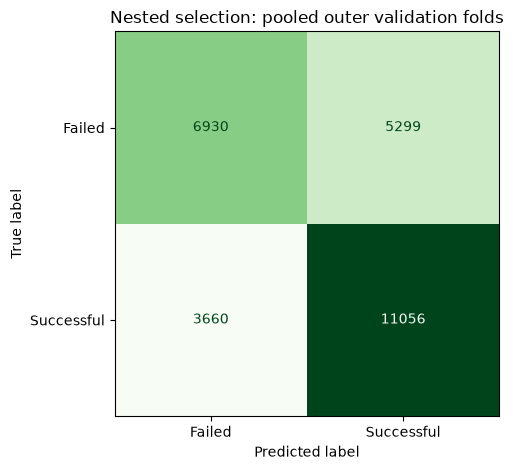

,accuracy,roc_auc,brier,tn,fp,fn,tp,failure_precision,failure_recall,failure_f1,failure_support,success_precision,success_recall,success_f1,success_support
0,0.6675,0.7219,0.2105,6930,5299,3660,11056,0.6544,0.5667,0.6074,12229.0,0.676,0.7513,0.7117,14716.0


,threshold,failure_recall,success_recall,fp,fn,accuracy
0,0.4,0.3971,0.8744,7373,1848,0.6578
1,0.5,0.5667,0.7513,5299,3660,0.6675
2,0.6,0.7332,0.5776,3263,6216,0.6482


Threshold trade-off is descriptive only. Raising the threshold flags more campaigns as failed, including more successful campaigns. The saved threshold remains 0.5.


In [3]:
p = probabilities['Selection']
pred = p >= 0.5
ConfusionMatrixDisplay.from_predictions(y, pred, labels=[0, 1],
    display_labels=['Failed', 'Successful'], cmap='Greens', colorbar=False)
plt.title('Nested selection: pooled outer validation folds')
plt.tight_layout()
plt.show()
display(pd.DataFrame([metrics(y, p)]).round(4))
tradeoff = pd.DataFrame([dict(threshold=t, **metrics(y, p, t)) for t in [0.4, 0.5, 0.6]])
display(tradeoff[['threshold', 'failure_recall', 'success_recall', 'fp', 'fn', 'accuracy']].round(4))
print('Threshold trade-off is descriptive only. Raising the threshold flags more campaigns as failed, including more successful campaigns. The saved threshold remains 0.5.')

Calibration uses only pooled outer-fold probabilities. The curve compares mean predictions with observed success rates in ten quantile bins. We report Brier score against an outer-training-prior baseline. We do not fit a calibrator using these validation labels.

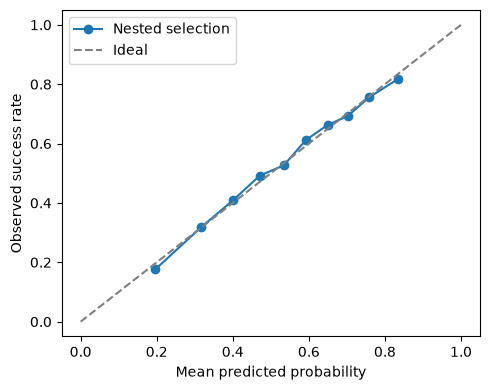

,mean_probability,observed_success_rate
0,0.1963,0.1763
1,0.3172,0.3185
2,0.4006,0.4089
3,0.4711,0.4922
4,0.5339,0.5262
5,0.5922,0.6117
6,0.6493,0.6626
7,0.7027,0.6931
8,0.7579,0.7554
9,0.8335,0.8167


Nested Brier: 0.2105
Outer-training-prior Brier: 0.2479


In [4]:
observed, predicted = calibration_curve(y, p, n_bins=10, strategy='quantile')
plt.figure(figsize=(5, 4))
plt.plot(predicted, observed, 'o-', label='Nested selection')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Ideal')
plt.xlabel('Mean predicted probability'); plt.ylabel('Observed success rate')
plt.legend(); plt.tight_layout(); plt.show()
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import brier_score_loss
prior_probability = np.empty(len(y))
for fit, valid in StratifiedKFold(3, shuffle=True, random_state=20261027).split(X, y):
    prior_probability[valid] = y.iloc[fit].mean()
calibration = pd.DataFrame({'mean_probability': predicted, 'observed_success_rate': observed})
display(calibration.round(4))
print('Nested Brier:', round(brier_score_loss(y, p), 4))
print('Outer-training-prior Brier:', round(brier_score_loss(y, prior_probability), 4))

Error groups use fixed goal and duration ranges and the recorded category. We show groups with at least 100 rows and at least 20 campaigns in each class. Smaller groups are omitted. These are descriptive diagnostics, not causal comparisons or reliable rankings of categories.

In [5]:
breakdowns = error_breakdowns(X, y, p)
display(breakdowns[['feature', 'group', 'n', 'accuracy', 'roc_auc', 'failure_recall',
                    'success_recall', 'fp', 'fn']].round(4))

,feature,group,n,accuracy,roc_auc,failure_recall,success_recall,fp,fn
0,goal,"(10000.0, 50000.0]",4220,0.6777,0.6806,0.8946,0.2505,295,1065
1,goal,"(5000.0, 10000.0]",4945,0.6222,0.6756,0.6656,0.5774,841,1027
2,goal,"(1000.0, 5000.0]",12394,0.6620,0.6922,0.4266,0.8168,2819,1370
3,goal,"(-0.001, 1000.0]",4822,0.6947,0.6346,0.1070,0.9611,1343,129
4,goal,"(50000.0, inf]",564,0.8759,0.6374,0.9980,0.0000,1,69
5,duration,"(60.0, 90.0]",2626,0.6394,0.6954,0.7399,0.5133,380,567
6,duration,"(15.0, 30.0]",10565,0.6737,0.7168,0.4800,0.8193,2357,1090
7,duration,"(30.0, 45.0]",7659,0.6675,0.7129,0.5359,0.7608,1475,1072
8,duration,"(45.0, 60.0]",4625,0.6614,0.7261,0.6812,0.6395,774,792
9,duration,"(0.0, 15.0]",1104,0.6957,0.6816,0.2533,0.9269,283,53


We select the final candidate with two-fold training CV, fit the complete conservative pipeline on all official training rows, and save it locally. The artifact and metadata are ignored by Git. Predictions and probabilities must match exactly after serialization on every training row. Re-running this cell replaces version 1 locally; freeze the version before sharing it.

Selected: HGB tuned
Parameters: {'categorical_features': 'from_dtype', 'class_weight': None, 'early_stopping': 'auto', 'interaction_cst': None, 'l2_regularization': 0.0026915045092098205, 'learning_rate': 0.04318571864689941, 'loss': 'log_loss', 'max_bins': 255, 'max_depth': None, 'max_features': 1.0, 'max_iter': 219, 'max_leaf_nodes': 14, 'min_samples_leaf': 43, 'monotonic_cst': None, 'n_iter_no_change': 10, 'random_state': 42, 'scoring': 'loss', 'tol': 1e-07, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}
Saved: /Users/annasehgal/State-Street-1C-kickstarter-crowdfunding-recommendation-engine/models/us_primary_model_v1.joblib
Serialization verified rows: 26945


{'success_probability': 0.425835168817201,
 'predicted_class': 0,
 'classification': 'failed',
 'threshold': 0.5}

Training-only restricted-candidate nested CV; candidates informed by prior tuning. Not a nested replay of the original searches or an independent holdout. Historical exposure of 1,486 reserved U.S. IDs; no reserved evaluation performed. Listed state/DC is a location proxy. Launch availability, duration meaning, snapshot provenance and goal currency remain unverified. Probabilities are uncalibrated.
Primary HGB validation: {'accuracy': 0.6693264056411208, 'roc_auc': 0.7239421770258075, 'brier': 0.20958354373448698, 'tn': 6814, 'fp': 5415, 'fn': 3495, 'tp': 11221, 'failure_precision': 0.6609758463478513, 'failure_recall': 0.5572000981274021, 'failure_f1': 0.6046676723755435, 'failure_support': 12229.0, 'success_precision': 0.6745010819908632, 'success_recall': 0.7625033976624083, 'success_f1': 0.7158076039806073, 'success_support': 14716.0}


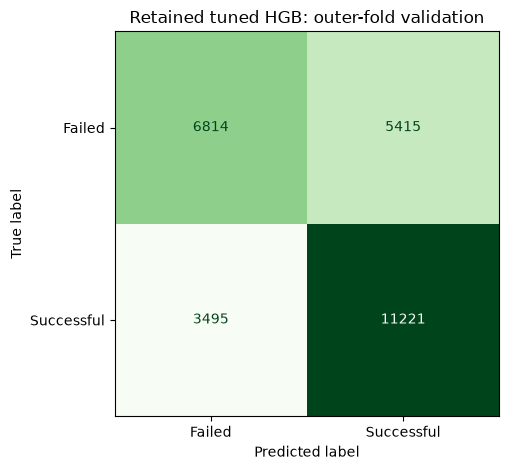

,feature,group,n,accuracy,roc_auc,failure_recall,fp,fn
0,goal,"(10000.0, 50000.0]",4220,0.6815,0.6880,0.9043,268,1076
1,goal,"(5000.0, 10000.0]",4945,0.6237,0.6801,0.6461,890,971
2,goal,"(1000.0, 5000.0]",12394,0.6638,0.6921,0.4046,2927,1240
3,goal,"(-0.001, 1000.0]",4822,0.6954,0.6363,0.1157,1330,139
4,goal,"(50000.0, inf]",564,0.8777,0.7143,1.0000,0,69
5,duration,"(60.0, 90.0]",2626,0.6333,0.6889,0.7290,396,567
6,duration,"(15.0, 30.0]",10565,0.6740,0.7205,0.4955,2287,1157
7,duration,"(30.0, 45.0]",7659,0.6741,0.7142,0.4880,1627,869
8,duration,"(45.0, 60.0]",4625,0.6644,0.7275,0.6804,776,776
9,duration,"(0.0, 15.0]",1104,0.6929,0.6594,0.2243,294,45


,mean_probability,observed_success_rate
0,0.1788,0.1722
1,0.3124,0.3244
2,0.4019,0.4026
3,0.4768,0.4792
4,0.5408,0.5384
5,0.6009,0.6140
6,0.6555,0.6537
7,0.7046,0.6983
8,0.7538,0.7602
9,0.8182,0.8186


In [6]:
model, metadata = save_primary(X, y, project_ids, summary, folds, ROOT)
print('Selected:', metadata['selected_candidate'])
print('Parameters:', metadata['estimator_parameters'])
print('Saved:', ROOT / 'models/us_primary_model_v1.joblib')
print('Serialization verified rows:', metadata['serialization_verified_rows'])
from utils.us_prediction import USPredictor
predictor = USPredictor(ROOT / 'models/us_primary_model_v1.joblib')
display(predictor.predict(dict(goal=5000, duration=30, category='Art',
                             subcategory='Painting', location='CA')))
print(LIMITATIONS)
import json
primary_p = probabilities['HGB']
primary_errors = error_breakdowns(X, y, primary_p)
observed_primary, predicted_primary = calibration_curve(y, primary_p, n_bins=10, strategy='quantile')
metadata['primary_calibration_bins'] = pd.DataFrame({
    'mean_probability': predicted_primary, 'observed_success_rate': observed_primary}).to_dict(orient='records')
metadata['primary_error_breakdowns'] = primary_errors.to_dict(orient='records')
metadata['baseline_brier'] = float(brier_score_loss(y, prior_probability))
(ROOT / 'models/us_primary_model_v1.metadata.json').write_text(json.dumps(metadata, indent=2, allow_nan=False) + '\n')
print('Primary HGB validation:', metadata['primary_validation_metrics'])
ConfusionMatrixDisplay.from_predictions(y, primary_p >= metadata['threshold'], labels=[0, 1],
    display_labels=['Failed', 'Successful'], cmap='Greens', colorbar=False)
plt.title('Retained tuned HGB: outer-fold validation')
plt.tight_layout(); plt.show()
display(primary_errors[['feature', 'group', 'n', 'accuracy', 'roc_auc', 'failure_recall', 'fp', 'fn']].round(4))
display(pd.DataFrame(metadata['primary_calibration_bins']).round(4))


The original audit found historical development exposure of 1,486 reserved U.S. IDs. Neither these folds nor the reserved partition establish a pristine holdout. Before any final reserved evaluation, Anna and Zasha should agree on the reporting protocol, freeze the model artifact, threshold and metrics, then authorize a separate evaluation. Report that result as retrospective evidence on historically exposed data. Do not retrain or change the threshold after seeing it. External or prospective validation would provide stronger evidence.